In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
import seaborn as sns
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

In [2]:
dataset = pd.read_csv("Non_Electric_Cleaned_DataSet.csv")

In [3]:
df = dataset.copy()

##  Dataset Understanding

In [4]:
df.head(5)

,Brand,Model,Rating,Rating_Members,Price(Rs),Engine(cc),Mileage(kmpl),Power(bhp),Weight(kg),Rating_Imputed,Rating_Clean
0,TVS,TVS Raider 125,4.4,2971.0,86943,124.80,56.70,11.2,123.0,False,4.4
1,Royal Enfield,Royal Enfield Hunter 350,4.7,1843.0,137640,349.34,36.20,20.2,181.0,False,4.7
2,Royal Enfield,Royal Enfield Classic 350,4.7,82.0,188934,349.00,41.55,20.2,195.0,False,4.7
3,Royal Enfield,Royal Enfield Bullet 350,4.7,1593.0,166981,349.00,35.00,20.2,195.0,False,4.7
4,TVS,TVS Ronin,4.6,1181.0,130809,225.90,42.00,20.1,160.0,False,4.6


In [5]:
df.describe()

,Rating,Rating_Members,Price(Rs),Engine(cc),Mileage(kmpl),Power(bhp),Weight(kg),Rating_Clean
count,335.000000,335.000000,3.350000e+02,335.000000,335.000000,335.000000,335.000000,256.000000
mean,4.440896,297.146269,8.254927e+05,532.991343,33.488030,54.674090,177.753731,4.402344
std,0.464648,730.873245,1.134244e+06,461.202837,14.726942,51.610907,55.292865,0.514948
min,1.700000,0.000000,4.792200e+04,49.900000,12.000000,4.290000,45.000000,1.700000
25%,4.400000,3.000000,1.373335e+05,156.450000,21.100000,14.675000,136.000000,4.400000
50%,4.500000,17.000000,2.892520e+05,349.000000,30.000000,36.490000,180.000000,4.500000
75%,4.700000,188.000000,1.321400e+06,870.500000,44.500000,84.590000,210.000000,4.700000
max,4.900000,4883.000000,1.000000e+07,2458.000000,80.000000,221.000000,390.000000,4.900000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 335 entries, 0 to 334
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Brand           335 non-null    object 
 1   Model           335 non-null    object 
 2   Rating          335 non-null    float64
 3   Rating_Members  335 non-null    float64
 4   Price(Rs)       335 non-null    int64  
 5   Engine(cc)      335 non-null    float64
 6   Mileage(kmpl)   335 non-null    float64
 7   Power(bhp)      335 non-null    float64
 8   Weight(kg)      335 non-null    float64
 9   Rating_Imputed  335 non-null    bool   
 10  Rating_Clean    256 non-null    float64
dtypes: bool(1), float64(7), int64(1), object(2)
memory usage: 26.6+ KB


In [7]:
df.shape

(335, 11)

In [8]:
df.columns

Index(['Brand', 'Model', 'Rating', 'Rating_Members', 'Price(Rs)', 'Engine(cc)',
       'Mileage(kmpl)', 'Power(bhp)', 'Weight(kg)', 'Rating_Imputed',
       'Rating_Clean'],
      dtype='object')

In [9]:
df.select_dtypes(include = "number").head(5)

,Rating,Rating_Members,Price(Rs),Engine(cc),Mileage(kmpl),Power(bhp),Weight(kg),Rating_Clean
0,4.4,2971.0,86943,124.80,56.70,11.2,123.0,4.4
1,4.7,1843.0,137640,349.34,36.20,20.2,181.0,4.7
2,4.7,82.0,188934,349.00,41.55,20.2,195.0,4.7
3,4.7,1593.0,166981,349.00,35.00,20.2,195.0,4.7
4,4.6,1181.0,130809,225.90,42.00,20.1,160.0,4.6


In [10]:
df.select_dtypes(include = "object").head(5)   # category columns

,Brand,Model
0,TVS,TVS Raider 125
1,Royal Enfield,Royal Enfield Hunter 350
2,Royal Enfield,Royal Enfield Classic 350
3,Royal Enfield,Royal Enfield Bullet 350
4,TVS,TVS Ronin


##  Outlier Analysis

In [11]:
q1 = df["Price(Rs)"].quantile(0.25)
q3 = df["Price(Rs)"].quantile(0.75)

iqr = q3-q1
lower_bound =  q1-1.5*iqr
upper_bound = q3 + 1.5*iqr

df[(df["Price(Rs)"] < lower_bound)|( df["Price(Rs)"] > upper_bound)].sort_values(by="Price(Rs)")

,Brand,Model,Rating,Rating_Members,Price(Rs),Engine(cc),Mileage(kmpl),Power(bhp),Weight(kg),Rating_Imputed,Rating_Clean
282,Ducati,Ducati XDiavel V4,4.40,0.0,3150960,1158.0,15.0,166.28,236.0,True,NaN
334,Ducati,Ducati Multistrada V4 Rally,4.40,0.0,3240000,1158.0,15.0,167.62,238.0,True,NaN
181,Ducati,Ducati Panigale V4,4.80,23.0,3269958,1103.0,15.0,219.00,188.0,False,4.8
240,Aprilia,Aprilia RSV4 1100 Factory,4.35,5.0,3340763,1099.0,19.8,213.89,202.0,True,NaN
184,Honda,Honda CBR1000RR-R Fireblade,3.50,5.0,3350000,1000.0,19.0,214.56,201.0,False,3.5
201,BMW,BMW M 1000 R,1.70,2.0,3350000,999.0,15.6,206.50,210.0,False,1.7
252,Harley-Davidson,Harley-Davidson Breakout,4.80,2.0,3436000,1923.0,17.8,101.90,310.0,True,NaN
190,Kawasaki,Kawasaki Ninja H2 SX SE,4.90,15.0,3627783,998.0,23.0,197.20,268.0,False,4.9
258,BMW,BMW K 1600,4.80,9.0,3800000,1649.0,17.0,158.00,358.0,True,NaN
292,Harley-Davidson,Harley-Davidson Street Glide,4.80,3.0,4250000,1923.0,16.0,107.20,368.0,True,NaN


In [12]:
q1 = df["Engine(cc)"].quantile(0.25)
q3 = df["Engine(cc)"].quantile(0.75)

iqr = q3-q1
lower_bound =  q1-1.5*iqr
upper_bound = q3 + 1.5*iqr

df[(df["Engine(cc)"] < lower_bound)|( df["Engine(cc)"] > upper_bound)].sort_values(by="Engine(cc)")

,Brand,Model,Rating,Rating_Members,Price(Rs),Engine(cc),Mileage(kmpl),Power(bhp),Weight(kg),Rating_Imputed,Rating_Clean
178,Triumph,Triumph Rocket 3,4.7,64.0,2401955,2458.0,14.6,165.0,304.0,False,4.7


In [13]:
q1 = df["Mileage(kmpl)"].quantile(0.25)
q3 = df["Mileage(kmpl)"].quantile(0.75)

iqr = q3-q1
lower_bound =  q1-1.5*iqr
upper_bound = q3 + 1.5*iqr

df[(df["Mileage(kmpl)"] < lower_bound)|( df["Mileage(kmpl)"] > upper_bound)].sort_values(by="Mileage(kmpl)")

,Brand,Model,Rating,Rating_Members,Price(Rs),Engine(cc),Mileage(kmpl),Power(bhp),Weight(kg),Rating_Imputed,Rating_Clean
75,TVS,TVS Sport,4.4,1682.0,65729,109.7,80.0,8.08,112.0,False,4.4


In [14]:
q1 = df["Power(bhp)"].quantile(0.25)
q3 = df["Power(bhp)"].quantile(0.75)

iqr = q3-q1
lower_bound =  q1-1.5*iqr
upper_bound = q3 + 1.5*iqr

df[(df["Power(bhp)"] < lower_bound)|( df["Power(bhp)"] > upper_bound)].sort_values(by="Power(bhp)")

,Brand,Model,Rating,Rating_Members,Price(Rs),Engine(cc),Mileage(kmpl),Power(bhp),Weight(kg),Rating_Imputed,Rating_Clean
142,Suzuki,Suzuki Hayabusa,4.80,34.0,1899000,1340.0,18.00,190.00,266.0,False,4.8
147,Kawasaki,Kawasaki Ninja ZX-10R,4.70,43.0,2079000,998.0,25.00,193.00,207.0,True,NaN
190,Kawasaki,Kawasaki Ninja H2 SX SE,4.90,15.0,3627783,998.0,23.00,197.20,268.0,False,4.9
241,Ducati,Ducati Streetfighter V4,4.40,3.0,2925963,1103.0,13.15,205.00,197.5,True,NaN
201,BMW,BMW M 1000 R,1.70,2.0,3350000,999.0,15.60,206.50,210.0,False,1.7
138,BMW,BMW S1000RR,4.80,62.0,2375000,999.0,16.00,206.51,197.0,False,4.8
240,Aprilia,Aprilia RSV4 1100 Factory,4.35,5.0,3340763,1099.0,19.80,213.89,202.0,True,NaN
184,Honda,Honda CBR1000RR-R Fireblade,3.50,5.0,3350000,1000.0,19.00,214.56,201.0,False,3.5
174,Ducati,Ducati Panigale V4 Lamborghini,4.10,8.0,10000000,1103.0,12.00,216.00,185.0,False,4.1
181,Ducati,Ducati Panigale V4,4.80,23.0,3269958,1103.0,15.00,219.00,188.0,False,4.8


In [15]:
q1 = df["Weight(kg)"].quantile(0.25)
q3 = df["Weight(kg)"].quantile(0.75)

iqr = q3-q1
lower_bound =  q1-1.5*iqr
upper_bound = q3 + 1.5*iqr

df[(df["Weight(kg)"] < lower_bound)|( df["Weight(kg)"] > upper_bound)].sort_values(by="Weight(kg)")

,Brand,Model,Rating,Rating_Members,Price(Rs),Engine(cc),Mileage(kmpl),Power(bhp),Weight(kg),Rating_Imputed,Rating_Clean
293,Harley-Davidson,Harley-Davidson Heritage Classic,4.80,0.0,2571000,1868.0,18.0,93.87,330.0,True,NaN
302,Indian,Indian Super Chief Limited,4.75,6.0,2438944,1890.0,14.0,107.20,335.0,True,NaN
258,BMW,BMW K 1600,4.80,9.0,3800000,1649.0,17.0,158.00,358.0,True,NaN
292,Harley-Davidson,Harley-Davidson Street Glide,4.80,3.0,4250000,1923.0,16.0,107.20,368.0,True,NaN
243,Harley-Davidson,Harley-Davidson Road Glide,3.30,2.0,4575000,1923.0,16.0,107.20,380.0,False,3.3
192,Honda,Honda Goldwing,3.30,2.0,4430000,1833.0,16.0,124.70,390.0,False,3.3


## Feature Engineering

In [16]:
df['Price_Segment']   = pd.qcut(df['Price(Rs)'],     3, labels=['Budget', 'Mid', 'Premium'])
df['Mileage_Segment'] = pd.qcut(df['Mileage(kmpl)'], 3, labels=['Low', 'Medium', 'High'])

In [17]:
num_cols = ['Price(Rs)', 'Engine(cc)','Mileage(kmpl)', 'Power(bhp)', 'Weight(kg)']

# Exploratory Data Analysis & Visualization


## Univariate Analysis

### Price(Rs) Column

In [18]:
print("Mean of Price:- Rs ",round(df["Price(Rs)"].mean(),2),"\n")
print("Median of Price:- Rs ",round(df["Price(Rs)"].median(),2),"\n")
print("Mode of Price:- Rs\n",round(df["Price(Rs)"].mode(),2),"\n")

Mean of Price:- Rs  825492.71 

Median of Price:- Rs  289252.0 

Mode of Price:- Rs
 0     219000
1     863000
2    1217000
3    1351600
4    3350000
Name: Price(Rs), dtype: int64 



In [19]:
col = 'Price(Rs)'
data = df[col].dropna()

price_min, price_max = data.min(), data.max()
price_range = price_max - price_min

variance = data.var()

std_dev = data.std()

q1 = data.quantile(0.25)
q3 = data.quantile(0.75)
iqr = q3 - q1

dispersion = pd.DataFrame({
    'Measure': ['Minimum', 'Maximum', 'Range', 'Variance', 'Standard Deviation', 'Q1 (25%)', 'Q3 (75%)', 'IQR'],
    'Value': [price_min, price_max, price_range, variance, std_dev, q1, q3, iqr]
})
dispersion['Value'] = dispersion['Value'].apply(lambda v: f'{v:,.2f}')
dispersion

,Measure,Value
0,Minimum,"47,922.00"
1,Maximum,"10,000,000.00"
2,Range,"9,952,078.00"
3,Variance,"1,286,509,789,052.48"
4,Standard Deviation,"1,134,244.15"
5,Q1 (25%),"137,333.50"
6,Q3 (75%),"1,321,400.00"
7,IQR,"1,184,066.50"


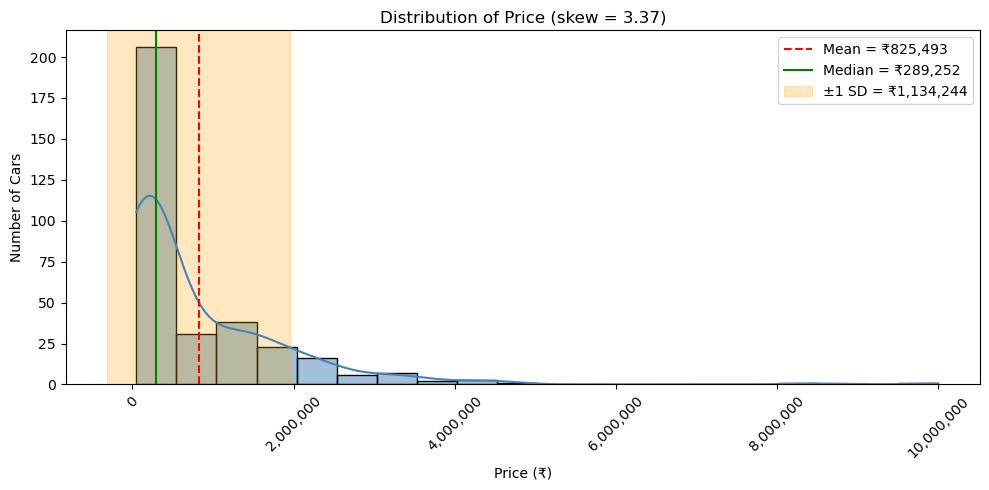

In [20]:
col = 'Price(Rs)'

plt.figure(figsize=(10, 5))
sns.histplot(df[col], bins=20, kde=True, color='steelblue', edgecolor='black')

plt.axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean = ₹{df[col].mean():,.0f}')
plt.axvline(df[col].median(), color='green', linestyle='-', label=f'Median = ₹{df[col].median():,.0f}')
plt.axvspan(df[col].mean() - df[col].std(), df[col].mean() + df[col].std(), color='orange', alpha=0.25,
            label=f'±1 SD = ₹{df[col].std():,.0f}')


plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.xticks(rotation=45)

plt.title(f'Distribution of Price (skew = {df[col].skew():.2f})')
plt.xlabel('Price (₹)')
plt.ylabel('Number of Cars')
plt.legend()
plt.tight_layout()
plt.show()

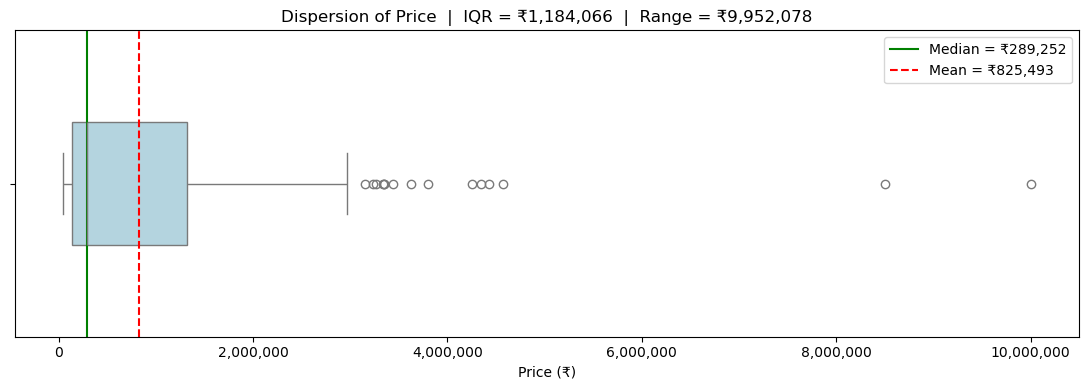

In [21]:
col = 'Price(Rs)'
q1, q3 = df[col].quantile([0.25, 0.75])
iqr = q3 - q1

plt.figure(figsize=(11, 4))
sns.boxplot(x=df[col], color='lightblue', width=0.4)

plt.axvline(df[col].median(), color='green', ls='-', label=f'Median = ₹{df[col].median():,.0f}')
plt.axvline(df[col].mean(), color='red', ls='--', label=f'Mean = ₹{df[col].mean():,.0f}')

plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.title(f'Dispersion of Price  |  IQR = ₹{iqr:,.0f}  |  Range = ₹{df[col].max()-df[col].min():,.0f}')
plt.xlabel('Price (₹)')
plt.legend()
plt.tight_layout()
plt.show()

### Engine(cc) Column

In [22]:
print("Mean of Engine(cc):- ",round(df["Engine(cc)"].mean(),2),"\n")
print("Median of Engine(cc):-  ",round(df["Engine(cc)"].median(),2),"\n")
print("Mode of Engine(cc):- ",round(df["Engine(cc)"].mode(),2),"\n")

Mean of Engine(cc):-  532.99 

Median of Engine(cc):-   349.0 

Mode of Engine(cc):-  0    649.0
Name: Engine(cc), dtype: float64 



In [23]:
col = 'Engine(cc)'
data = df[col].dropna()

price_min, price_max = data.min(), data.max()
price_range = price_max - price_min

variance = data.var()

std_dev = data.std()

q1 = data.quantile(0.25)
q3 = data.quantile(0.75)
iqr = q3 - q1

dispersion = pd.DataFrame({
    'Measure': ['Minimum', 'Maximum', 'Range', 'Variance', 'Standard Deviation', 'Q1 (25%)', 'Q3 (75%)', 'IQR'],
    'Value': [price_min, price_max, price_range, variance, std_dev, q1, q3, iqr]
})
dispersion['Value'] = dispersion['Value'].apply(lambda v: f'{v:,.2f}')
dispersion

,Measure,Value
0,Minimum,49.90
1,Maximum,"2,458.00"
2,Range,"2,408.10"
3,Variance,"212,708.06"
4,Standard Deviation,461.20
5,Q1 (25%),156.45
6,Q3 (75%),870.50
7,IQR,714.05


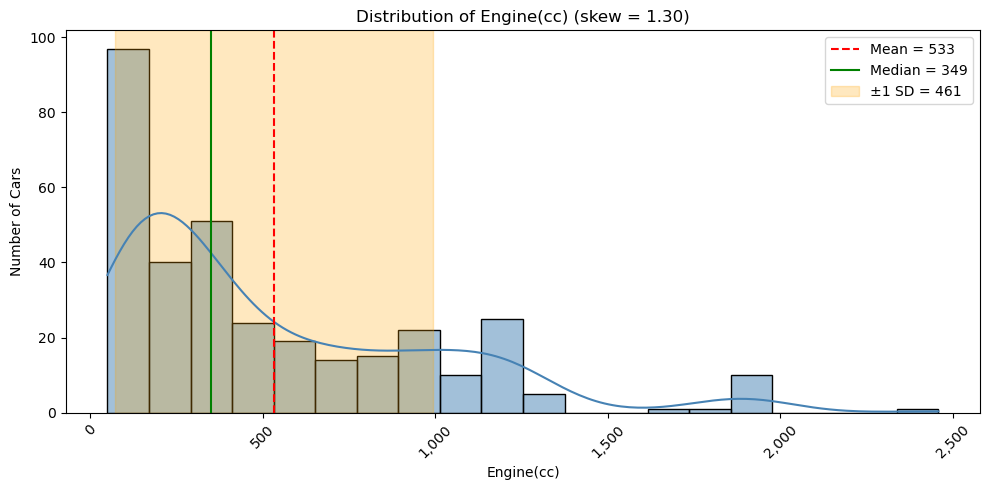

In [24]:
col = 'Engine(cc)'

plt.figure(figsize=(10, 5))
sns.histplot(df[col], bins=20, kde=True, color='steelblue', edgecolor='black')

plt.axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean = {df[col].mean():,.0f}')
plt.axvline(df[col].median(), color='green', linestyle='-', label=f'Median = {df[col].median():,.0f}')
plt.axvspan(df[col].mean() - df[col].std(), df[col].mean() + df[col].std(), color='orange', alpha=0.25,
            label=f'±1 SD = {df[col].std():,.0f}')


plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.xticks(rotation=45)

plt.title(f'Distribution of Engine(cc) (skew = {df[col].skew():.2f})')
plt.xlabel('Engine(cc)')
plt.ylabel('Number of Cars')
plt.legend()
plt.tight_layout()
plt.show()

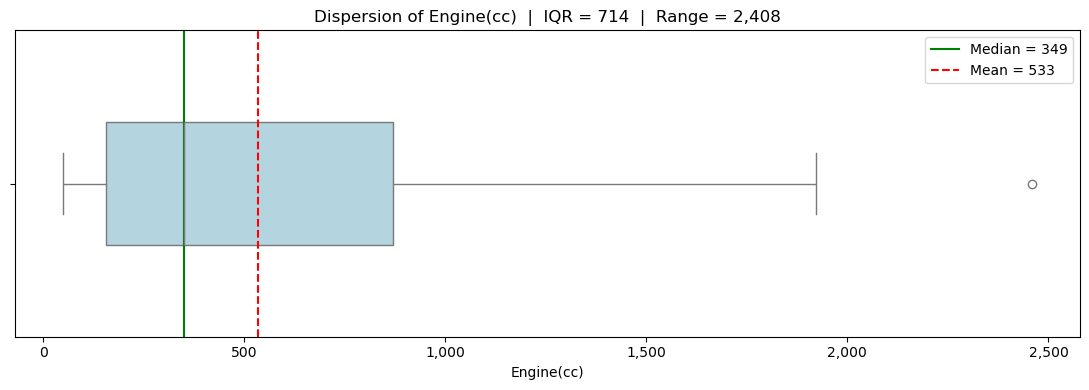

In [25]:
col = 'Engine(cc)'
q1, q3 = df[col].quantile([0.25, 0.75])
iqr = q3 - q1

plt.figure(figsize=(11, 4))
sns.boxplot(x=df[col], color='lightblue', width=0.4)

plt.axvline(df[col].median(), color='green', ls='-', label=f'Median = {df[col].median():,.0f}')
plt.axvline(df[col].mean(), color='red', ls='--', label=f'Mean = {df[col].mean():,.0f}')

plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.title(f'Dispersion of Engine(cc)  |  IQR = {iqr:,.0f}  |  Range = {df[col].max()-df[col].min():,.0f}')
plt.xlabel('Engine(cc)')
plt.legend()
plt.tight_layout()
plt.show()

### Mileage(kmpl) Column

In [26]:
print("Mean of Mileage(kmpl):- ",round(df["Mileage(kmpl)"].mean(),2),"\n")
print("Median of Mileage(kmpl):-  ",round(df["Mileage(kmpl)"].median(),2),"\n")
print("Mode of Mileage(kmpl):- ",round(df["Mileage(kmpl)"].mode(),2),"\n")

Mean of Mileage(kmpl):-  33.49 

Median of Mileage(kmpl):-   30.0 

Mode of Mileage(kmpl):-  0    21.0
Name: Mileage(kmpl), dtype: float64 



In [27]:
col = 'Mileage(kmpl)'
data = df[col].dropna()

price_min, price_max = data.min(), data.max()
price_range = price_max - price_min

variance = data.var()

std_dev = data.std()

q1 = data.quantile(0.25)
q3 = data.quantile(0.75)
iqr = q3 - q1

dispersion = pd.DataFrame({
    'Measure': ['Minimum', 'Maximum', 'Range', 'Variance', 'Standard Deviation', 'Q1 (25%)', 'Q3 (75%)', 'IQR'],
    'Value': [price_min, price_max, price_range, variance, std_dev, q1, q3, iqr]
})
dispersion['Value'] = dispersion['Value'].apply(lambda v: f'{v:,.2f}')
dispersion

,Measure,Value
0,Minimum,12.00
1,Maximum,80.00
2,Range,68.00
3,Variance,216.88
4,Standard Deviation,14.73
5,Q1 (25%),21.10
6,Q3 (75%),44.50
7,IQR,23.40


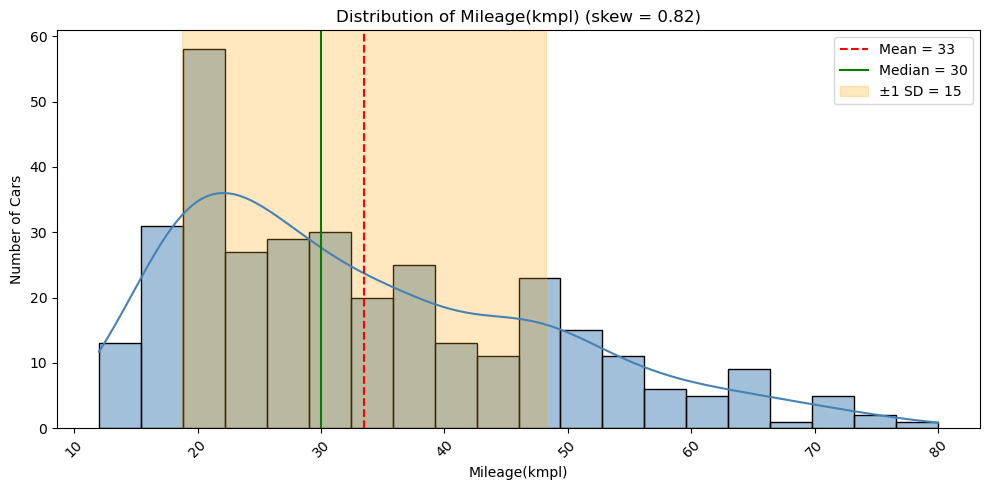

In [28]:
col = 'Mileage(kmpl)'

plt.figure(figsize=(10, 5))
sns.histplot(df[col], bins=20, kde=True, color='steelblue', edgecolor='black')

plt.axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean = {df[col].mean():,.0f}')
plt.axvline(df[col].median(), color='green', linestyle='-', label=f'Median = {df[col].median():,.0f}')
plt.axvspan(df[col].mean() - df[col].std(), df[col].mean() + df[col].std(), color='orange', alpha=0.25,
            label=f'±1 SD = {df[col].std():,.0f}')


plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.xticks(rotation=45)

plt.title(f'Distribution of Mileage(kmpl) (skew = {df[col].skew():.2f})')
plt.xlabel('Mileage(kmpl)')
plt.ylabel('Number of Cars')
plt.legend()
plt.tight_layout()
plt.show()

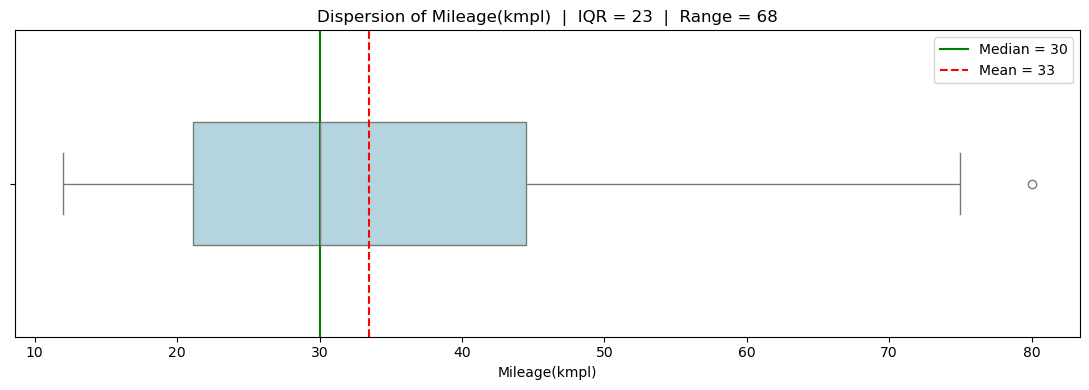

In [29]:
col = 'Mileage(kmpl)'
q1, q3 = df[col].quantile([0.25, 0.75])
iqr = q3 - q1

plt.figure(figsize=(11, 4))
sns.boxplot(x=df[col], color='lightblue', width=0.4)

plt.axvline(df[col].median(), color='green', ls='-', label=f'Median = {df[col].median():,.0f}')
plt.axvline(df[col].mean(), color='red', ls='--', label=f'Mean = {df[col].mean():,.0f}')

plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.title(f'Dispersion of Mileage(kmpl)  |  IQR = {iqr:,.0f}  |  Range = {df[col].max()-df[col].min():,.0f}')
plt.xlabel('Mileage(kmpl)')
plt.legend()
plt.tight_layout()
plt.show()

### Power(bhp) Column

In [30]:
print("Mean of Power(bhp):- ",round(df["Power(bhp)"].mean(),2),"\n")
print("Median of Power(bhp):-  ",round(df["Power(bhp)"].median(),2),"\n")
print("Mode of Power(bhp):- ",round(df["Power(bhp)"].mode(),2),"\n")

Mean of Power(bhp):-  54.67 

Median of Power(bhp):-   36.49 

Mode of Power(bhp):-  0     8.48
1    12.20
Name: Power(bhp), dtype: float64 



In [31]:
col = 'Power(bhp)'
data = df[col].dropna()

price_min, price_max = data.min(), data.max()
price_range = price_max - price_min

variance = data.var()

std_dev = data.std()

q1 = data.quantile(0.25)
q3 = data.quantile(0.75)
iqr = q3 - q1

dispersion = pd.DataFrame({
    'Measure': ['Minimum', 'Maximum', 'Range', 'Variance', 'Standard Deviation', 'Q1 (25%)', 'Q3 (75%)', 'IQR'],
    'Value': [price_min, price_max, price_range, variance, std_dev, q1, q3, iqr]
})
dispersion['Value'] = dispersion['Value'].apply(lambda v: f'{v:,.2f}')
dispersion

,Measure,Value
0,Minimum,4.29
1,Maximum,221.00
2,Range,216.71
3,Variance,"2,663.69"
4,Standard Deviation,51.61
5,Q1 (25%),14.68
6,Q3 (75%),84.59
7,IQR,69.92


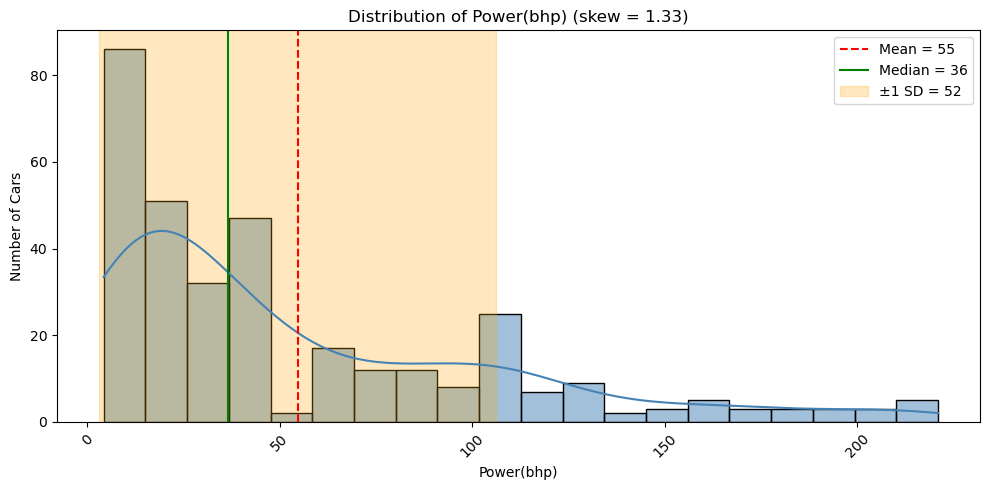

In [32]:
col = 'Power(bhp)'

plt.figure(figsize=(10, 5))
sns.histplot(df[col], bins=20, kde=True, color='steelblue', edgecolor='black')

plt.axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean = {df[col].mean():,.0f}')
plt.axvline(df[col].median(), color='green', linestyle='-', label=f'Median = {df[col].median():,.0f}')
plt.axvspan(df[col].mean() - df[col].std(), df[col].mean() + df[col].std(), color='orange', alpha=0.25,
            label=f'±1 SD = {df[col].std():,.0f}')


plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.xticks(rotation=45)

plt.title(f'Distribution of Power(bhp) (skew = {df[col].skew():.2f})')
plt.xlabel('Power(bhp)')
plt.ylabel('Number of Cars')
plt.legend()
plt.tight_layout()
plt.show()

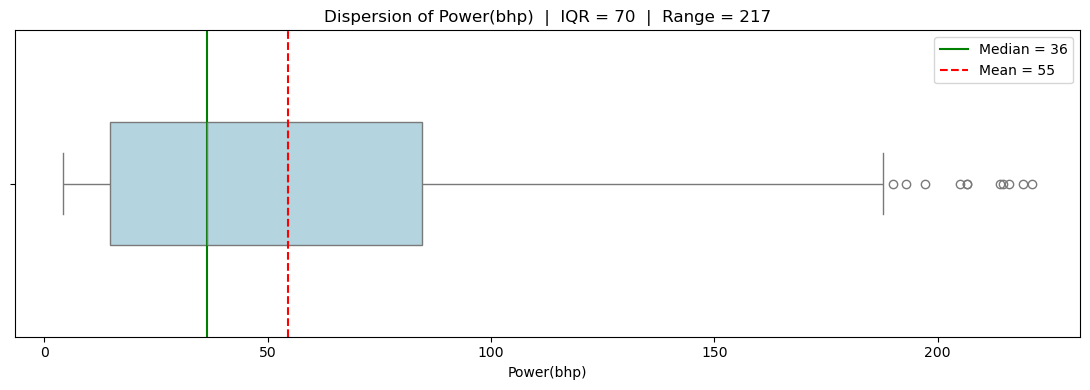

In [33]:
col = 'Power(bhp)'
q1, q3 = df[col].quantile([0.25, 0.75])
iqr = q3 - q1

plt.figure(figsize=(11, 4))
sns.boxplot(x=df[col], color='lightblue', width=0.4)

plt.axvline(df[col].median(), color='green', ls='-', label=f'Median = {df[col].median():,.0f}')
plt.axvline(df[col].mean(), color='red', ls='--', label=f'Mean = {df[col].mean():,.0f}')

plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.title(f'Dispersion of Power(bhp)  |  IQR = {iqr:,.0f}  |  Range = {df[col].max()-df[col].min():,.0f}')
plt.xlabel('Power(bhp)')
plt.legend()
plt.tight_layout()
plt.show()

### Weight(kg) Column

In [34]:
print("Mean of Weight(kg):- ",round(df["Weight(kg)"].mean(),2),"\n")
print("Median of Weight(kg):-  ",round(df["Weight(kg)"].median(),2),"\n")
print("Mode of Weight(kg):- ",round(df["Weight(kg)"].mode(),2),"\n") 

Mean of Weight(kg):-  177.75 

Median of Weight(kg):-   180.0 

Mode of Weight(kg):-  0    115.0
Name: Weight(kg), dtype: float64 



In [35]:
col = 'Weight(kg)'
data = df[col].dropna()

price_min, price_max = data.min(), data.max()
price_range = price_max - price_min

variance = data.var()

std_dev = data.std()

q1 = data.quantile(0.25)
q3 = data.quantile(0.75)
iqr = q3 - q1

dispersion = pd.DataFrame({
    'Measure': ['Minimum', 'Maximum', 'Range', 'Variance', 'Standard Deviation', 'Q1 (25%)', 'Q3 (75%)', 'IQR'],
    'Value': [price_min, price_max, price_range, variance, std_dev, q1, q3, iqr]
})
dispersion['Value'] = dispersion['Value'].apply(lambda v: f'{v:,.2f}')
dispersion

,Measure,Value
0,Minimum,45.00
1,Maximum,390.00
2,Range,345.00
3,Variance,"3,057.30"
4,Standard Deviation,55.29
5,Q1 (25%),136.00
6,Q3 (75%),210.00
7,IQR,74.00


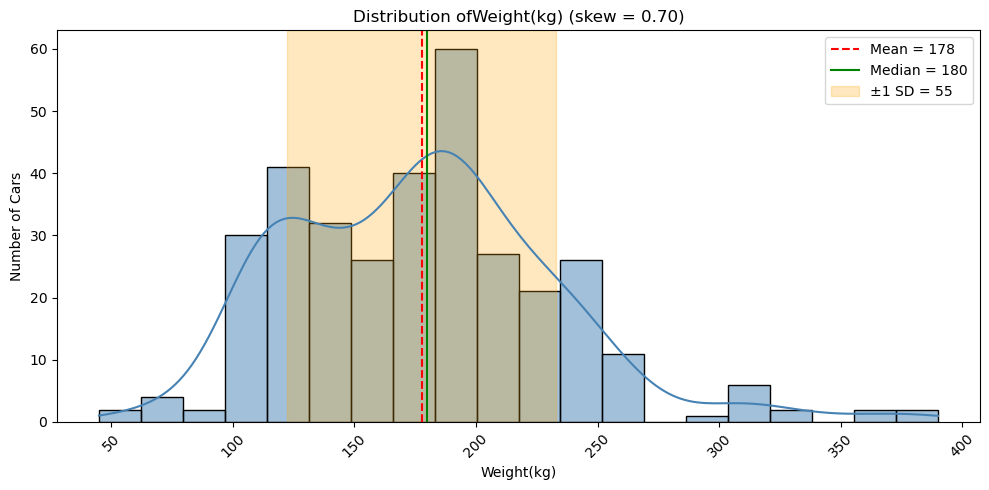

In [36]:
col = 'Weight(kg)'

plt.figure(figsize=(10, 5))
sns.histplot(df[col], bins=20, kde=True, color='steelblue', edgecolor='black')

plt.axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean = {df[col].mean():,.0f}')
plt.axvline(df[col].median(), color='green', linestyle='-', label=f'Median = {df[col].median():,.0f}')
plt.axvspan(df[col].mean() - df[col].std(), df[col].mean() + df[col].std(), color='orange', alpha=0.25,
            label=f'±1 SD = {df[col].std():,.0f}')


plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.xticks(rotation=45)

plt.title(f'Distribution ofWeight(kg) (skew = {df[col].skew():.2f})')
plt.xlabel('Weight(kg)')
plt.ylabel('Number of Cars')
plt.legend()
plt.tight_layout()
plt.show()


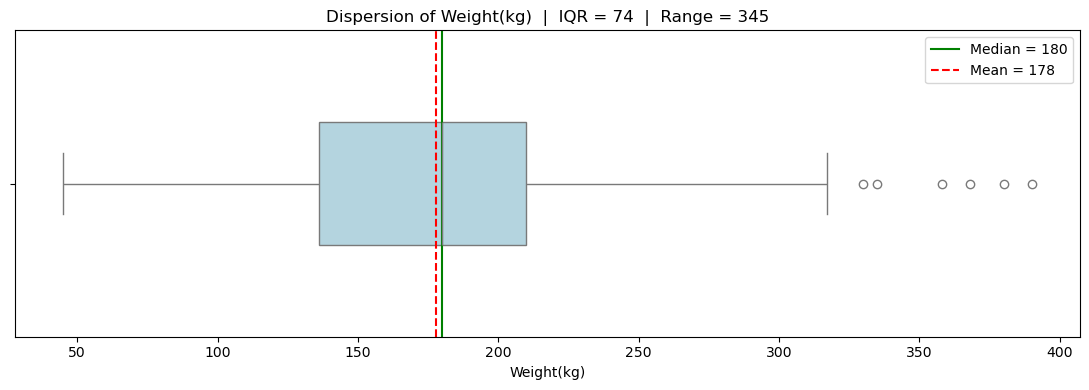

In [37]:
col = 'Weight(kg)'
q1, q3 = df[col].quantile([0.25, 0.75])
iqr = q3 - q1

plt.figure(figsize=(11, 4))
sns.boxplot(x=df[col], color='lightblue', width=0.4)

plt.axvline(df[col].median(), color='green', ls='-', label=f'Median = {df[col].median():,.0f}')
plt.axvline(df[col].mean(), color='red', ls='--', label=f'Mean = {df[col].mean():,.0f}')

plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.title(f'Dispersion of Weight(kg)  |  IQR = {iqr:,.0f}  |  Range = {df[col].max()-df[col].min():,.0f}')
plt.xlabel('Weight(kg)')
plt.legend()
plt.tight_layout()
plt.show()

### Brand Column

In [38]:
col = 'Brand'   

count = df[col].value_counts()
percent = df[col].value_counts(normalize=True).mul(100)

table = pd.DataFrame({'Count': count, 'Percent (%)': percent})
table['Cumulative (%)'] = table['Percent (%)'].cumsum()
table

,Count,Percent (%),Cumulative (%)
Brand,,,
Kawasaki,37,11.044776,11.044776
Triumph,30,8.955224,20.000000
Honda,25,7.462687,27.462687
Hero,25,7.462687,34.925373
KTM,24,7.164179,42.089552
Ducati,21,6.268657,48.358209
Bajaj,20,5.970149,54.328358
TVS,19,5.671642,60.000000
Royal Enfield,16,4.776119,64.776119


In [39]:
print('Number of categories :', df[col].nunique())

Number of categories : 28


In [40]:
print('Most common (mode)   :', df[col].mode()[0])

Most common (mode)   : Kawasaki


In [41]:
print('Least common :', count[count == count.min()], f'({count.min()} records)')

Least common : Brand
VLF           1
Moto Guzzi    1
Name: count, dtype: int64 (1 records)


In [42]:
print('Top category share   :', f'{percent.iloc[0]}%')

Top category share   : 11.044776119402986%


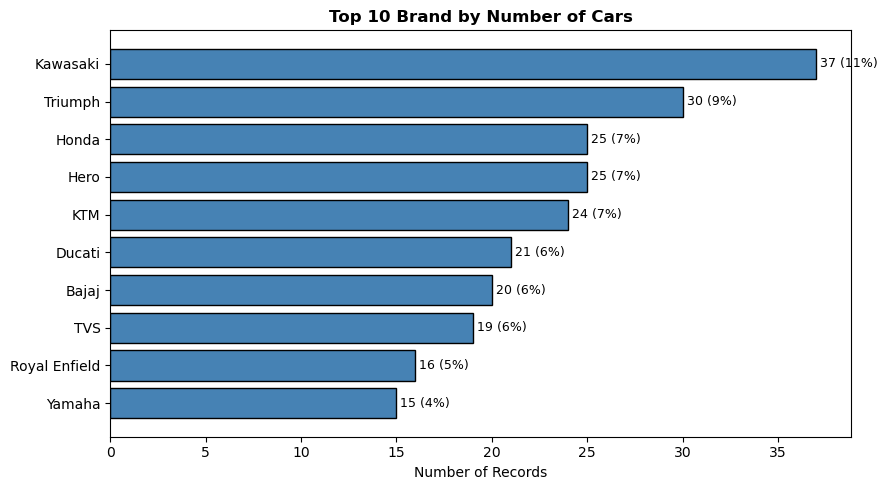

In [43]:
top = count.head(10)

plt.figure(figsize=(9, 5))
plt.barh(top.index.astype(str)[::-1], top.values[::-1], color='steelblue', edgecolor='black')

for i, (c, p) in enumerate(zip(top.values[::-1], percent.head(10).values[::-1])):
    plt.text(c, i, f' {c} ({p:.0f}%)', va='center', fontsize=9)

plt.title(f'Top 10 {col} by Number of Cars', fontweight='bold')
plt.xlabel('Number of Records')
plt.tight_layout()
plt.show()

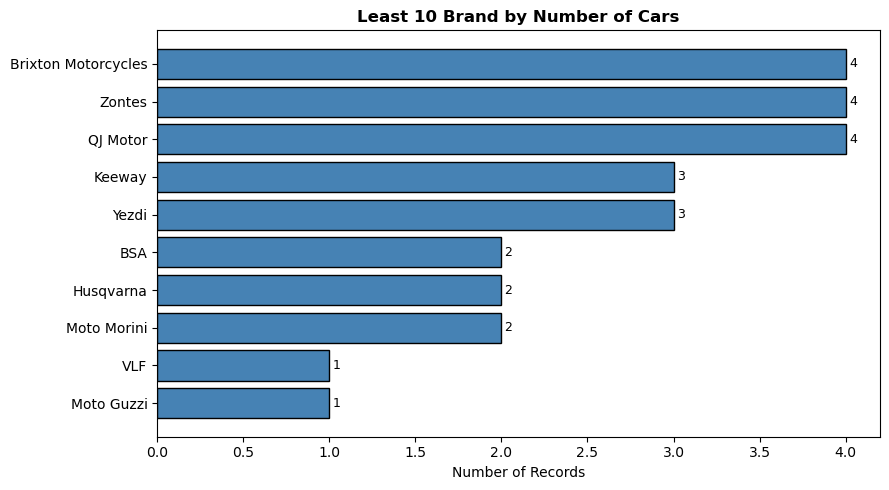

In [44]:
top = count.tail(10)

plt.figure(figsize=(9, 5))
plt.barh(top.index.astype(str)[::-1], top.values[::-1], color='steelblue', edgecolor='black')

for i, (c, p) in enumerate(zip(top.values[::-1], percent.head(10).values[::-1])):
    plt.text(c, i, f' {c}', va='center', fontsize=9)

plt.title(f'Least 10 {col} by Number of Cars', fontweight='bold')
plt.xlabel('Number of Records')
plt.tight_layout()
plt.show()

### Model Column

In [45]:
df["Model"].nunique()  # Different Models 

335

## Bivariate Analysis

### Numerical vs Numerical Analysis

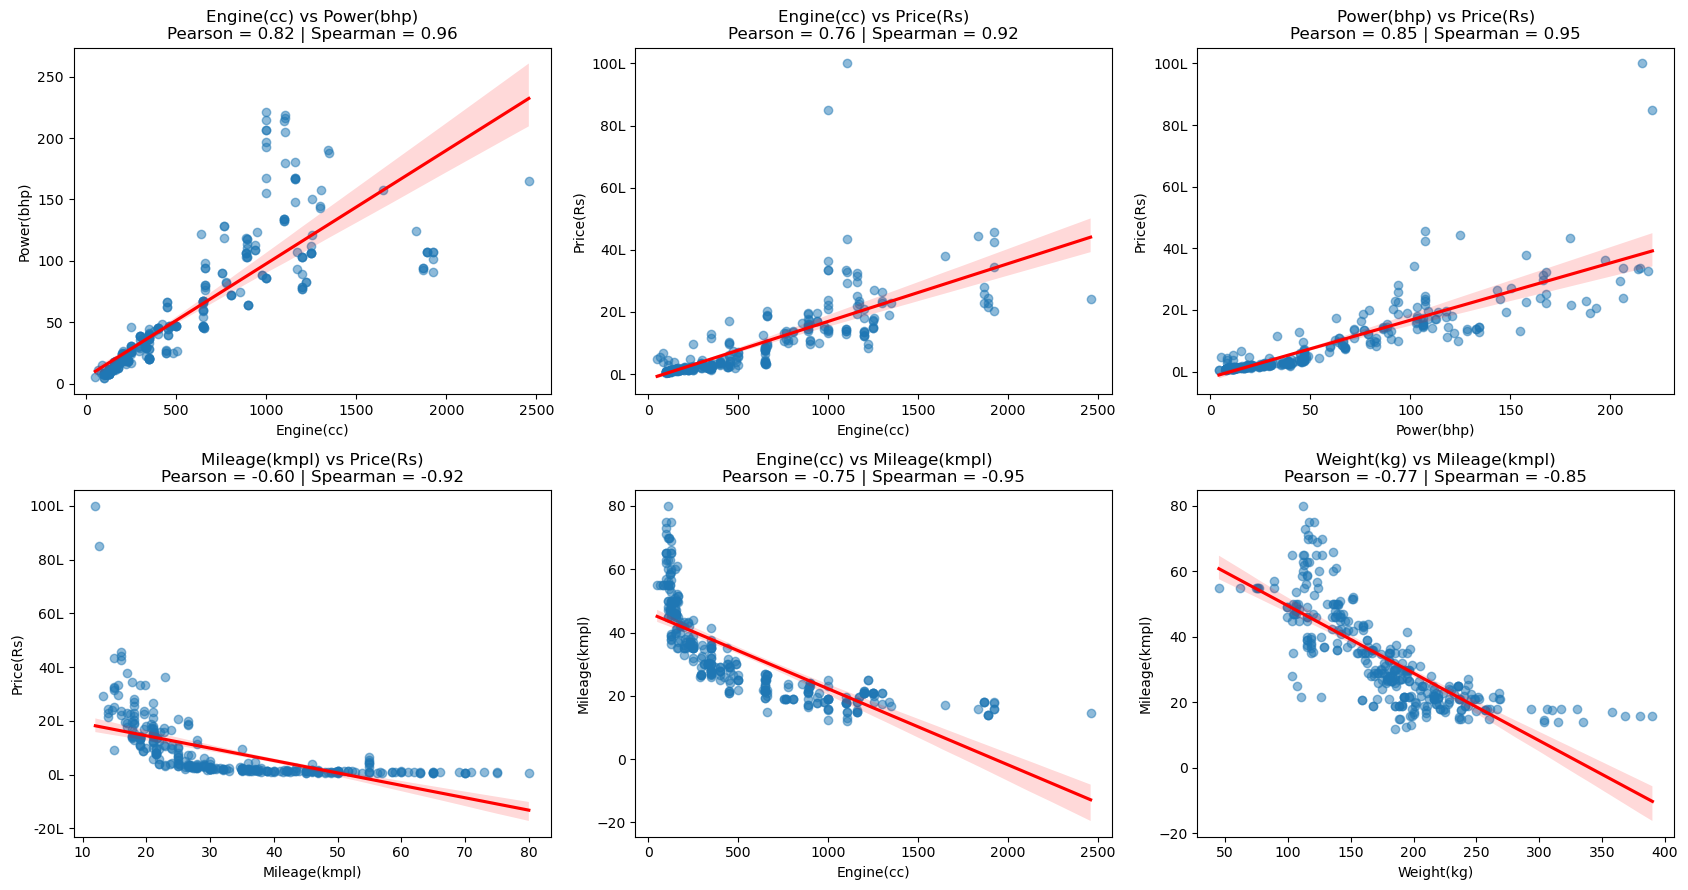

In [46]:
pairs = [('Engine(cc)', 'Power(bhp)'), ('Engine(cc)', 'Price(Rs)'),
         ('Power(bhp)', 'Price(Rs)'), ('Mileage(kmpl)', 'Price(Rs)'),
         ('Engine(cc)', 'Mileage(kmpl)'), ('Weight(kg)', 'Mileage(kmpl)')]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (x, y) in zip(axes.flatten(), pairs):
    sub = df[[x, y]].dropna()
    r = sub[x].corr(sub[y])                       
    rho = sub[x].corr(sub[y], method='spearman')
    sns.regplot(data=sub, x=x, y=y, ax=ax, scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
    ax.set_title(f'{x} vs {y}\nPearson = {r:.2f} | Spearman = {rho:.2f}')
    if y == 'Price(Rs)':
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v/1e5:.0f}L'))
plt.tight_layout()
plt.show()

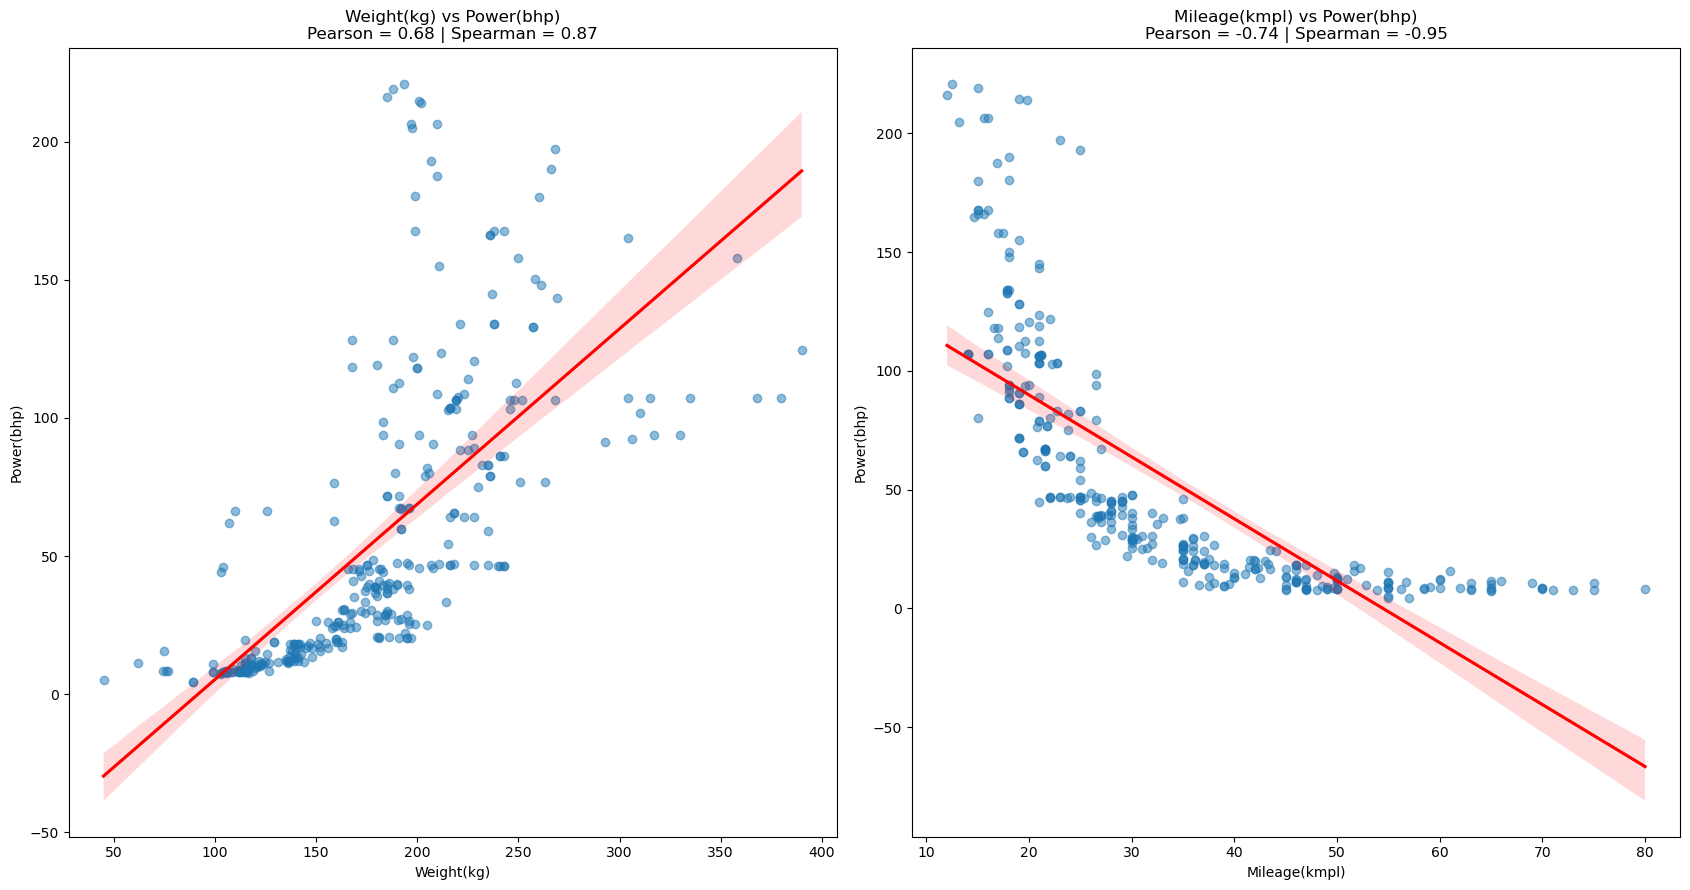

In [47]:
pairs = [('Weight(kg)', 'Power(bhp)'), ('Mileage(kmpl)' ,'Power(bhp)')]

fig, axes = plt.subplots(1, 2, figsize=(17, 9))
for ax, (x, y) in zip(axes.flatten(), pairs):
    sub = df[[x, y]].dropna()
    r = sub[x].corr(sub[y])                       # Pearson
    rho = sub[x].corr(sub[y], method='spearman')  # Spearman
    sns.regplot(data=sub, x=x, y=y, ax=ax, scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
    ax.set_title(f'{x} vs {y}\nPearson = {r:.2f} | Spearman = {rho:.2f}')
    if y == 'Price(Rs)':
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v/1e5:.0f}L'))
plt.tight_layout()
plt.show()

### Categorical vs Numerical Analysis

####  Which brands are most and least expensive?

In [48]:
df.groupby("Brand")["Price(Rs)"].median().sort_values()

Brand
Hero                     84523.0
TVS                      91056.0
Bajaj                   130964.0
VLF                     136999.0
Vespa                   138745.0
Yamaha                  141755.0
Keeway                  158985.0
Honda                   161295.0
Suzuki                  184550.0
Yezdi                   201981.0
Jawa                    203545.0
Husqvarna               264090.0
Zontes                  266015.0
Aprilia                 268090.0
QJ Motor                269509.5
Royal Enfield           279546.0
BSA                     332245.0
KTM                     369565.0
Moto Morini             539584.0
Benelli                 620982.0
Brixton Motorcycles     660527.5
Kawasaki                768968.0
Triumph                1217000.0
Indian                 1505802.0
Moto Guzzi             1645802.0
Ducati                 1950975.0
BMW                    2250000.0
Harley-Davidson        2296480.0
Name: Price(Rs), dtype: float64

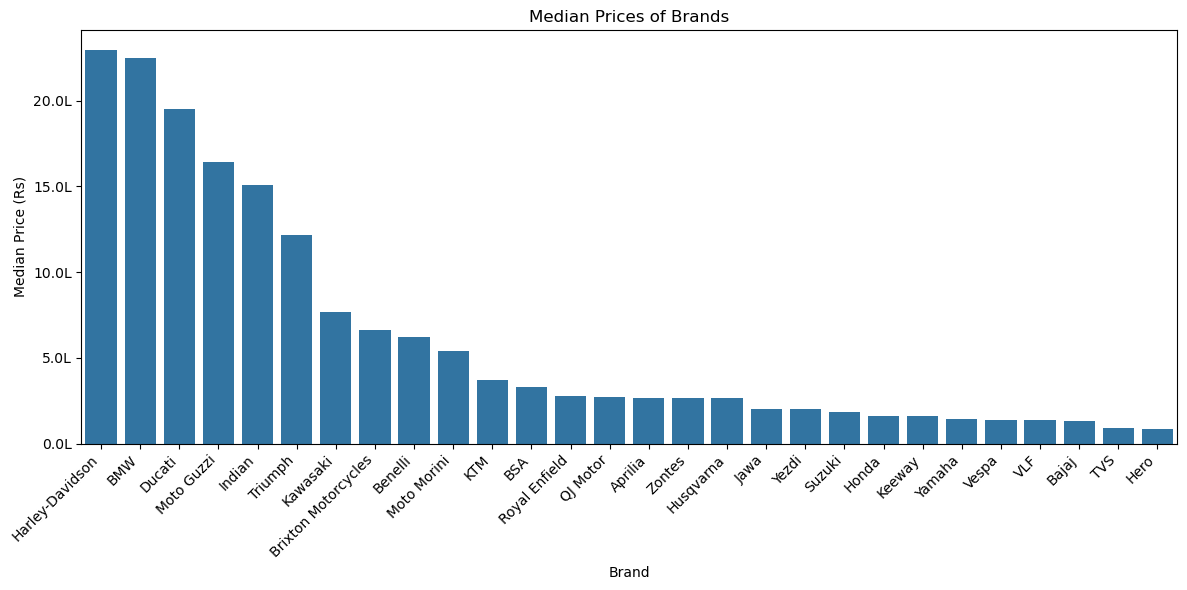

In [49]:
brand_order = (
    df.groupby("Brand")["Price(Rs)"].median().sort_values(ascending=False).index
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=df,
    x="Brand",
    y="Price(Rs)",
    order = brand_order,
    estimator="median",
    errorbar=None,
)

plt.title("Median Prices of Brands")
plt.xlabel("Brand")
plt.ylabel("Median Price (Rs)")
ax = plt.gca()
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1e5:.1f}L"))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### Which brands sell the most models?

In [50]:
df["Brand"].value_counts()

Brand
Kawasaki               37
Triumph                30
Honda                  25
Hero                   25
KTM                    24
Ducati                 21
Bajaj                  20
TVS                    19
Royal Enfield          16
Yamaha                 15
BMW                    13
Harley-Davidson        13
Suzuki                 13
Aprilia                12
Indian                 11
Vespa                   6
Jawa                    5
Benelli                 4
Brixton Motorcycles     4
Zontes                  4
QJ Motor                4
Keeway                  3
Yezdi                   3
BSA                     2
Husqvarna               2
Moto Morini             2
VLF                     1
Moto Guzzi              1
Name: count, dtype: int64

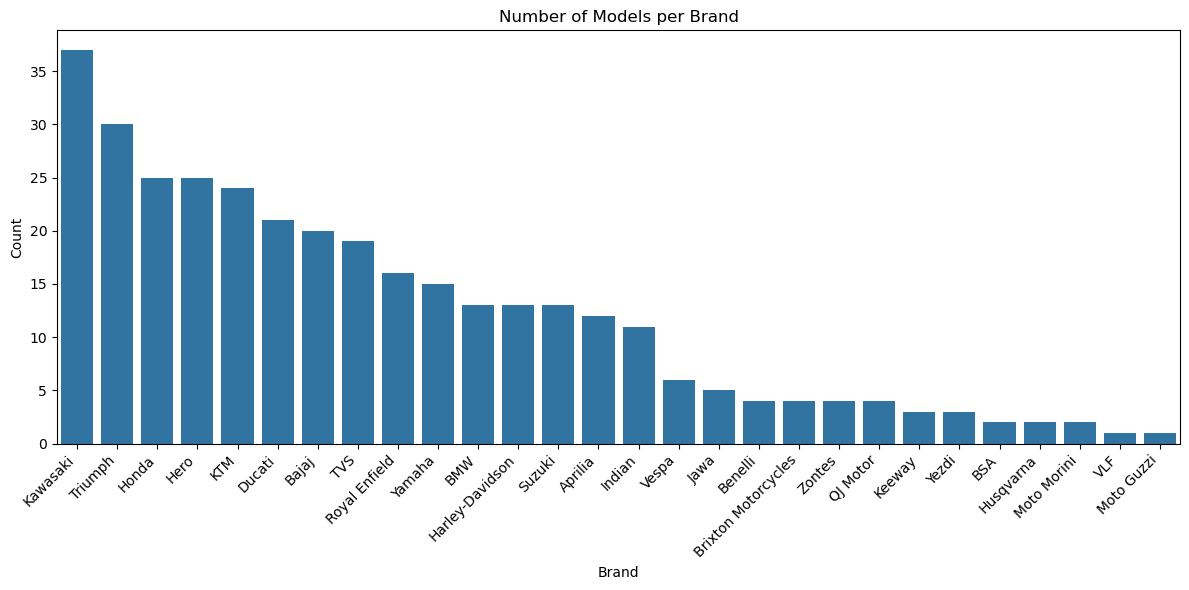

In [51]:
brand_order = df["Brand"].value_counts().index

plt.figure(figsize=(12, 6))
sns.countplot(
    data=df,
    x="Brand",
    order=brand_order,
)

plt.title("Number of Models per Brand")
plt.xlabel("Brand")
plt.ylabel("Count")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Categorical vs Categorical Analysis  

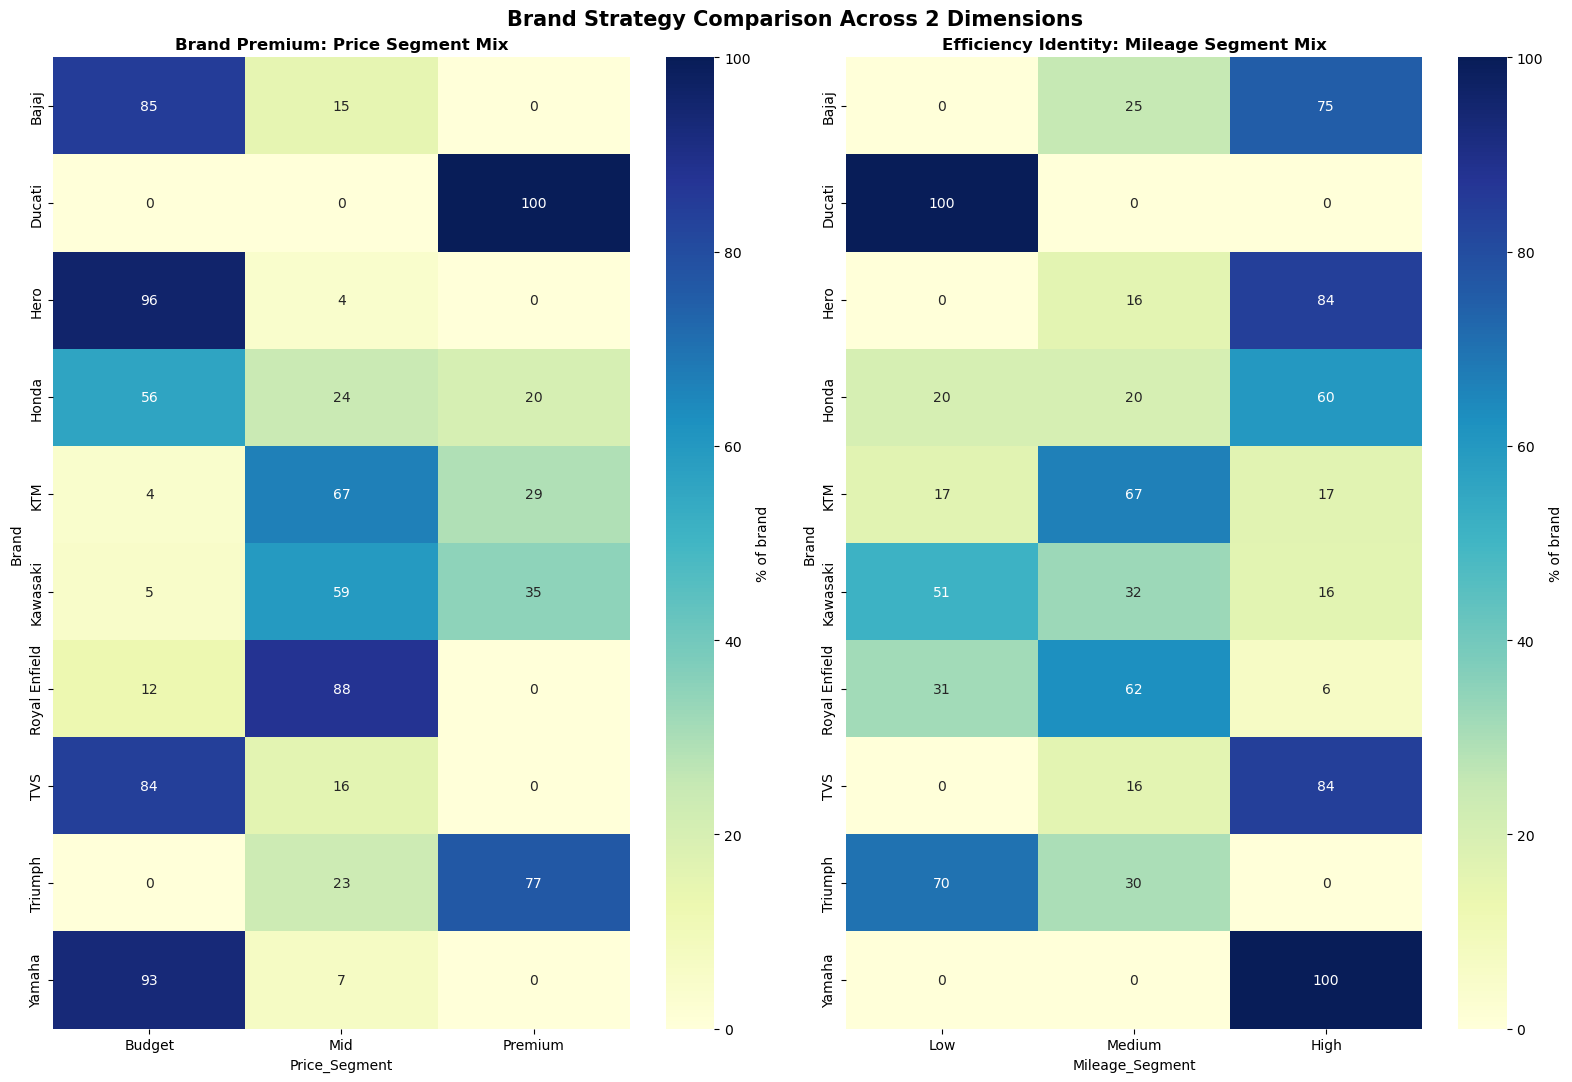

In [52]:
pairs = [
    'Price_Segment',
    'Mileage_Segment'
]

top_brands = df['Brand'].value_counts().head(10).index
sub = df[df['Brand'].isin(top_brands)]

fig, axes = plt.subplots(1, 2, figsize=(16, 11))

titles = [
    'Brand Premium: Price Segment Mix',
    'Efficiency Identity: Mileage Segment Mix'
]

for ax, col, title in zip(axes.flatten(), pairs, titles):

    ct = pd.crosstab(
        sub['Brand'],
        sub[col],
        normalize='index'
    ) * 100

    sns.heatmap(
        ct,
        annot=True,
        fmt='.0f',
        cmap='YlGnBu',
        cbar_kws={'label': '% of brand'},
        ax=ax
    )

    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Brand')

plt.suptitle(
    'Brand Strategy Comparison Across 2 Dimensions',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Price_Segment vs Mileage Segment')

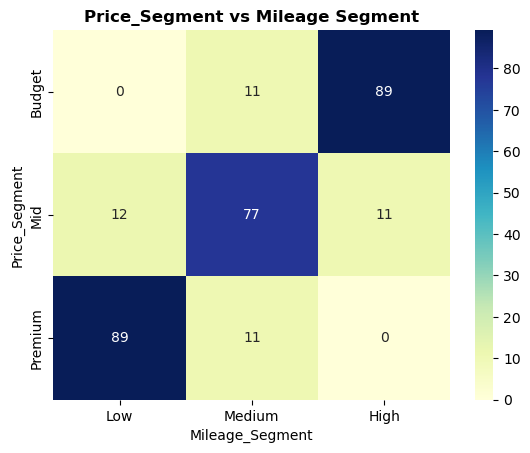

In [53]:
ct = pd.crosstab(
        df['Price_Segment'],
        df['Mileage_Segment'],
        normalize='index'
    ) * 100

sns.heatmap(
    ct,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu'
)

plt.title("Price_Segment vs Mileage Segment", fontweight='bold')

## Multivariate Analysis

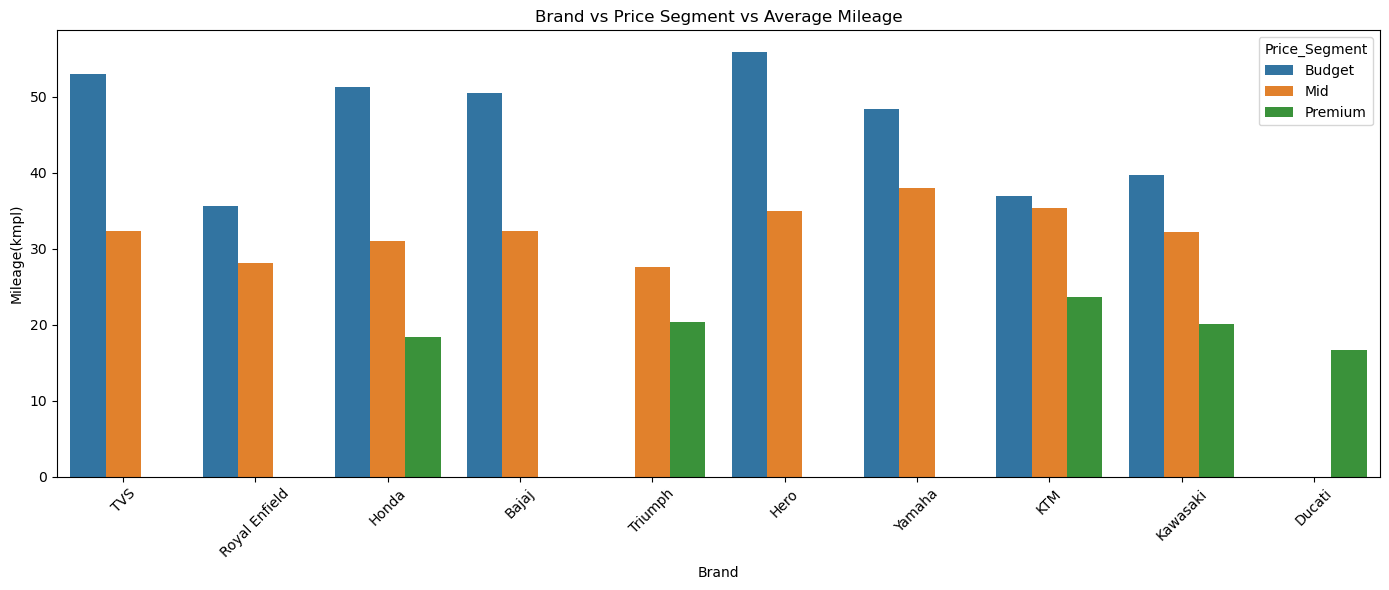

In [54]:
top_brands = df['Brand'].value_counts().head(10).index
sub = df[df['Brand'].isin(top_brands)]

plt.figure(figsize=(14, 6))

sns.barplot(
    data=sub,
    x='Brand',
    y='Mileage(kmpl)',
    hue='Price_Segment',
    errorbar=None
)

plt.xticks(rotation=45)
plt.title('Brand vs Price Segment vs Average Mileage')
plt.tight_layout()
plt.show()

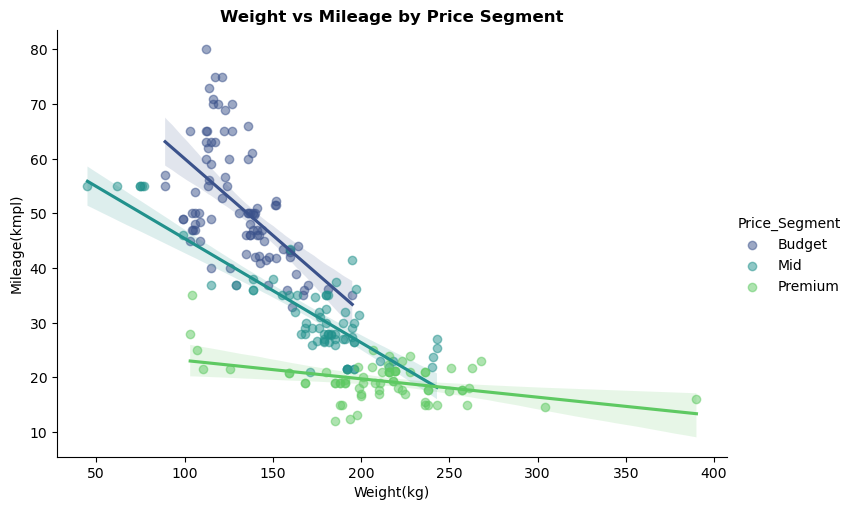

In [55]:
sns.lmplot(data=sub, x='Weight(kg)', y='Mileage(kmpl)', hue='Price_Segment',
           palette='viridis', height=5, aspect=1.5, scatter_kws={'alpha': 0.5})
plt.title('Weight vs Mileage by Price Segment', fontweight='bold')
plt.show()

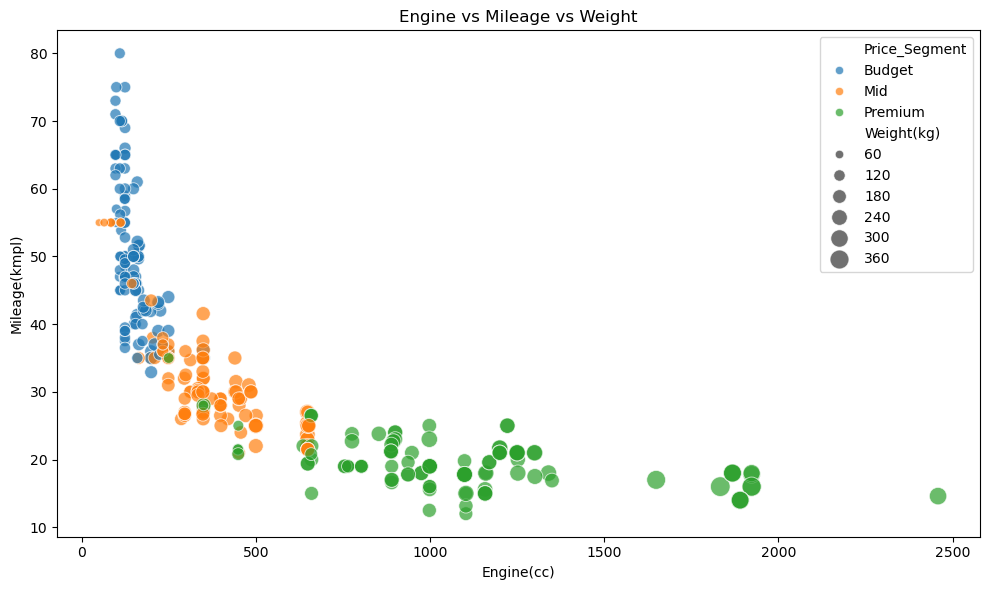

In [56]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Engine(cc)',
    y='Mileage(kmpl)',
    size='Weight(kg)',
    hue='Price_Segment',
    sizes=(30, 200),
    alpha=0.7
)

plt.title('Engine vs Mileage vs Weight')
plt.tight_layout()
plt.show()

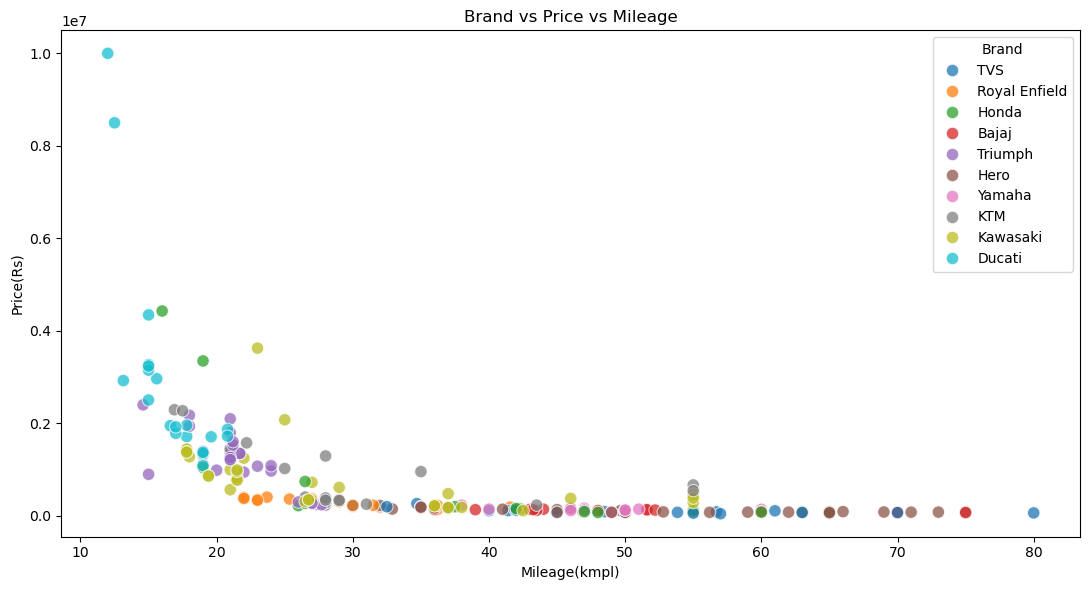

In [57]:
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=sub,
    x='Mileage(kmpl)',
    y='Price(Rs)',
    hue='Brand',
    alpha=0.75,
    s=80
)

plt.title('Brand vs Price vs Mileage')
plt.tight_layout()
plt.show()

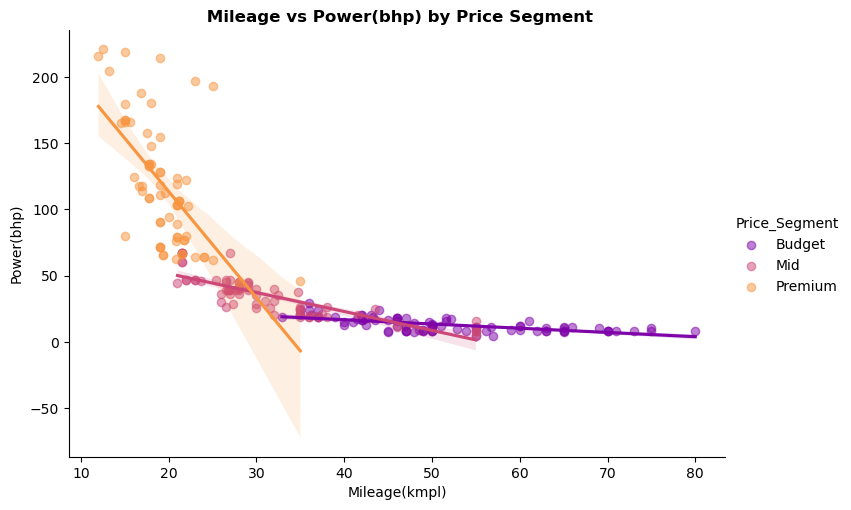

In [58]:
sns.lmplot(data=sub, y='Power(bhp)', x='Mileage(kmpl)', hue='Price_Segment',
           palette='plasma', height=5, aspect=1.5, scatter_kws={'alpha': 0.5})
plt.title(' Mileage vs Power(bhp) by Price Segment', fontweight='bold')
plt.show()

## Groupby Analysis

#### Which brands offer the most models under ₹1.5 lakh and compare thier specifications?

In [59]:
nums = ['Price(Rs)', 'Engine(cc)','Mileage(kmpl)', 'Power(bhp)', 'Weight(kg)']
df1=df[df["Price(Rs)"]<150000]
df1_summary = df1.groupby("Brand")[nums].agg({
    "Price(Rs)":['mean',"median","count"],
    "Engine(cc)": "mean",
    "Mileage(kmpl)": "mean",
    "Power(bhp)": "mean",
    "Weight(kg)": "mean"
})
df1_summary.map(lambda x : f"{x:.2f}")

Price(Rs)                   Engine(cc) Mileage(kmpl)  \
                    mean     median  count       mean          mean   
Brand                                                                 
Aprilia        119911.50  120179.50   6.00     147.13         37.75   
Bajaj          113981.62  122951.50  16.00     164.40         51.50   
Hero            90412.36   82501.00  22.00     123.00         57.71   
Honda           92144.45   91370.00  11.00     124.78         53.36   
Kawasaki       115006.00  115006.00   1.00     177.00         42.50   
Keeway         128987.00  128987.00   1.00     125.00         47.00   
QJ Motor       137027.00  137027.00   1.00     249.00         39.00   
Royal Enfield  137640.00  137640.00   1.00     349.34         36.20   
Suzuki         112208.17  110778.50   6.00     134.38         50.60   
TVS             91922.06   87401.50  16.00     137.25         52.96   
VLF            136999.00  136999.00   1.00     124.60         46.00   
Vespa          137559.50  138745.00   6.00     132.80         42.08   
Yamaha         121292.90  125868.00  10.00     144.80         49.20   

              Power(bhp) Weight(kg)  
                    mean       mean  
Brand                                
Aprilia            11.38     118.00  
Bajaj              15.48     144.75  
Hero               10.36     121.85  
Honda               9.70     115.36  
Kawasaki           12.80     135.00  
Keeway              9.56     120.00  
QJ Motor           17.16     163.00  
Royal Enfield      20.20     181.00  
Suzuki             10.08     121.00  
TVS                11.28     120.06  
VLF                12.00     122.00  
Vespa               9.99     115.00  
Yamaha             11.56     128.40

#### Which models offer the highest power under budget segment? - Performance on a budget

In [60]:
sub = df[df['Price(Rs)'] <= 183603].copy()


sub = sub[
    ['Brand', 'Model', 'Power(bhp)', 'Price(Rs)']
].dropna()


top_power_models = sub.sort_values(
    by='Power(bhp)',
    ascending=False
)

# Display top 10 models
top_power_models.head(10)

,Brand,Model,Power(bhp),Price(Rs)
54,Hero,Hero Xtreme 250R,29.50,172591
76,Hero,Hero Xpulse 210,24.20,168218
19,Bajaj,Bajaj Pulsar NS200,24.13,139257
51,Bajaj,Bajaj Pulsar RS 200,24.10,182014
37,Bajaj,Bajaj Pulsar N250,24.10,145519
79,TVS,TVS Apache RTR 200 4V,20.54,138353
1,Royal Enfield,Royal Enfield Hunter 350,20.20,137640
3,Royal Enfield,Royal Enfield Bullet 350,20.20,166981
86,Bajaj,Bajaj Pulsar 220F,20.11,140641
4,TVS,TVS Ronin,20.10,130809


#### Which brands offer the most affordable vehicles? Budget brands

In [61]:
df1 = df[df["Price(Rs)"]<183603].copy()
df1.groupby("Brand")["Model"].count()

Brand
Aprilia           6
Bajaj            17
Hero             24
Honda            14
Kawasaki          2
Keeway            2
QJ Motor          1
Royal Enfield     2
Suzuki            6
TVS              16
VLF               1
Vespa             6
Yamaha           14
Name: Model, dtype: int64

#### Which models offer the highest Mileage under budget segment?¶ - Fuel-efficient choices

In [62]:
df.groupby('Price_Segment', observed=True)['Price(Rs)'].agg(
    Min_Price='min',
    Max_Price='max'
)

,Min_Price,Max_Price
Price_Segment,,
Budget,47922,183603
Mid,184010,823000
Premium,823778,10000000


In [63]:
sub = df[df['Price(Rs)'] <= 183603].copy()


sub = sub[
    ['Brand', 'Model', 'Mileage(kmpl)', 'Power(bhp)','Price(Rs)']
].dropna()


top_power_models = sub.sort_values(
    by='Mileage(kmpl)',
    ascending=False
)

# Display top 10 models
top_power_models.head(10)

,Brand,Model,Mileage(kmpl),Power(bhp),Price(Rs)
75,TVS,TVS Sport,80.0,8.08,65729
96,Hero,Hero Super Splendor Xtec 2.0,75.0,10.70,86508
157,Bajaj,Bajaj Platina 100,75.0,7.79,71049
78,Hero,Hero Splendor Plus Xtec,73.0,7.90,82573
83,Hero,Hero Passion Plus,71.0,7.91,81048
172,TVS,TVS Star City Plus,70.0,8.08,72072
163,Bajaj,Bajaj CT 110,70.0,8.48,74848
158,Bajaj,Bajaj Platina 110,70.0,8.48,75819
131,Hero,Hero Super Splendor Xtec,69.0,10.72,84523
9,Hero,Hero Xtreme 125R,66.0,11.40,92855


####  Which brands are truly expensive vs just a few luxury models?

In [64]:
stats = df.groupby("Brand")["Price(Rs)"].agg(["mean", "median", "count"])
stats = stats[stats["count"] >= 5]

stats["gap"] = stats["mean"] - stats["median"]

print(stats.sort_values("mean", ascending=False).round(0))

                      mean     median  count       gap
Brand                                                 
Ducati           2893034.0  1950975.0     21  942059.0
Harley-Davidson  2306806.0  2296480.0     13   10326.0
BMW              2048835.0  2250000.0     13 -201165.0
Indian           1732763.0  1505802.0     11  226961.0
Triumph          1145374.0  1217000.0     30  -71626.0
Aprilia           889502.0   268090.0     12  621412.0
Kawasaki          801854.0   768968.0     37   32886.0
KTM               691654.0   369565.0     24  322089.0
Honda             592395.0   161295.0     25  431100.0
Suzuki            419410.0   184550.0     13  234860.0
Royal Enfield     284316.0   279546.0     16    4770.0
Jawa              201559.0   203545.0      5   -1986.0
Yamaha            139847.0   141755.0     15   -1908.0
Vespa             137560.0   138745.0      6   -1186.0
Bajaj             129672.0   130964.0     20   -1292.0
TVS               114022.0    91056.0     19   22966.0
Hero      

#### Top 10 Brands and thier Specifications

In [65]:
df.columns

Index(['Brand', 'Model', 'Rating', 'Rating_Members', 'Price(Rs)', 'Engine(cc)',
       'Mileage(kmpl)', 'Power(bhp)', 'Weight(kg)', 'Rating_Imputed',
       'Rating_Clean', 'Price_Segment', 'Mileage_Segment'],
      dtype='object')

In [66]:
brand_summary = (
    df.groupby('Brand')
    .agg(
        bikes=('Model', 'count'),
        avg_price=('Price(Rs)', 'mean'),
        median_price=('Price(Rs)', 'median'),
        avg_power=('Power(bhp)', 'mean'),
        avg_mileage=('Mileage(kmpl)', 'mean'),
        avg_weight=('Weight(kg)', 'mean')
    )
    .round(1)
    .sort_values('median_price', ascending=False)
)

brand_summary

,bikes,avg_price,median_price,avg_power,avg_mileage,avg_weight
Brand,,,,,,
Harley-Davidson,13,2306806.2,2296480.0,91.5,20.1,278.3
BMW,13,2048834.7,2250000.0,119.3,21.2,226.8
Ducati,21,2893033.6,1950975.0,135.9,16.7,204.4
Moto Guzzi,1,1645802.0,1645802.0,75.1,23.8,230.0
Indian,11,1732762.9,1505802.0,101.7,18.5,267.5
Triumph,30,1145374.4,1217000.0,86.4,22.1,212.2
Kawasaki,37,801853.5,768968.0,65.7,28.4,173.8
Brixton Motorcycles,4,673718.2,660527.5,65.3,27.5,213.8
Benelli,4,628964.5,620982.0,46.8,24.2,221.5


#### Price_Segment and Specifications

In [67]:
(df.groupby('Price_Segment', observed=True)[num_cols].median().round(1))

,Price(Rs),Engine(cc),Mileage(kmpl),Power(bhp),Weight(kg)
Price_Segment,,,,,
Budget,116085.0,125.0,47.0,11.4,122.8
Mid,289252.0,349.0,30.0,36.5,182.0
Premium,1677328.5,999.0,19.0,106.5,220.5


##  Pivot Table Analysis

In [68]:
p1 = df.pivot_table(index='Brand', columns='Price_Segment', values='Model',
                     aggfunc='count', fill_value=0, observed=True)

p1

Price_Segment,Budget,Mid,Premium
Brand,,,
Aprilia,6,2,4
BMW,0,2,11
BSA,0,2,0
Bajaj,17,3,0
Benelli,0,4,0
Brixton Motorcycles,0,2,2
Ducati,0,0,21
Harley-Davidson,0,2,11
Hero,24,1,0


In [69]:
p2 = df.pivot_table(index='Brand', columns='Price_Segment', values='Mileage(kmpl)',
                     aggfunc='mean', fill_value=0, observed=True)
p2

Price_Segment,Budget,Mid,Premium
Brand,,,
Aprilia,37.750000,26.500000,24.825000
BMW,0.000000,28.000000,19.927273
BSA,0.000000,25.000000,0.000000
Bajaj,50.532353,32.333333,0.000000
Benelli,0.000000,24.250000,0.000000
Brixton Motorcycles,0.000000,30.000000,25.000000
Ducati,0.000000,0.000000,16.745238
Harley-Davidson,0.000000,32.500000,17.800000
Hero,55.939583,35.000000,0.000000


In [70]:
p3 = df.pivot_table(index='Brand', columns='Price_Segment', values='Power(bhp)',
                     aggfunc='mean', fill_value=0, observed=True)
p3

Price_Segment,Budget,Mid,Premium
Brand,,,
Aprilia,11.385000,46.900000,121.360000
BMW,0.000000,41.085000,133.473636
BSA,0.000000,45.610000,0.000000
Bajaj,15.991176,35.570000,0.000000
Benelli,0.000000,46.800000,0.000000
Brixton Motorcycles,0.000000,47.600000,83.000000
Ducati,0.000000,0.000000,135.902857
Harley-Davidson,0.000000,27.185000,103.236364
Hero,11.734583,25.150000,0.000000


In [71]:
p4 = df.pivot_table(index='Brand', columns='Price_Segment', values='Weight(kg)',
                     aggfunc='mean', fill_value=0, observed=True)
p4

Price_Segment,Budget,Mid,Premium
Brand,,,
Aprilia,118.000000,175.000000,193.000000
BMW,0.000000,176.000000,236.000000
BSA,0.000000,204.500000,0.000000
Bajaj,146.058824,182.000000,0.000000
Benelli,0.000000,221.500000,0.000000
Brixton Motorcycles,0.000000,192.500000,235.000000
Ducati,0.000000,0.000000,204.428571
Harley-Davidson,0.000000,191.250000,294.181818
Hero,125.762500,163.500000,0.000000


## Crosstab Analysis

In [72]:
ct = pd.crosstab(df['Brand'], df['Price_Segment'], normalize='index').mul(100).round(1)
ct

Price_Segment,Budget,Mid,Premium
Brand,,,
Aprilia,50.0,16.7,33.3
BMW,0.0,15.4,84.6
BSA,0.0,100.0,0.0
Bajaj,85.0,15.0,0.0
Benelli,0.0,100.0,0.0
Brixton Motorcycles,0.0,50.0,50.0
Ducati,0.0,0.0,100.0
Harley-Davidson,0.0,15.4,84.6
Hero,96.0,4.0,0.0


In [73]:
ct = pd.crosstab(df['Brand'], df['Mileage_Segment'], normalize='index').mul(100)
ct

Mileage_Segment,Low,Medium,High
Brand,,,
Aprilia,8.333333,58.333333,33.333333
BMW,76.923077,23.076923,0.000000
BSA,0.000000,100.000000,0.000000
Bajaj,0.000000,25.000000,75.000000
Benelli,25.000000,75.000000,0.000000
Brixton Motorcycles,0.000000,100.000000,0.000000
Ducati,100.000000,0.000000,0.000000
Harley-Davidson,84.615385,15.384615,0.000000
Hero,0.000000,16.000000,84.000000


##  Covariance & Correlation Analysis

In [74]:
cov = df[num_cols].cov()
cov.round(1)

,Price(Rs),Engine(cc),Mileage(kmpl),Power(bhp),Weight(kg)
Price(Rs),1.286510e+12,395840494.6,-10015958.3,49504689.1,38273659.3
Engine(cc),3.958405e+08,212708.1,-5117.5,19626.1,22678.6
Mileage(kmpl),-1.001596e+07,-5117.5,216.9,-565.5,-629.9
Power(bhp),4.950469e+07,19626.1,-565.5,2663.7,1940.7
Weight(kg),3.827366e+07,22678.6,-629.9,1940.7,3057.3


               Price(Rs)  Engine(cc)  Mileage(kmpl)  Power(bhp)  Weight(kg)
Price(Rs)           1.00        0.76          -0.60        0.85        0.61
Engine(cc)          0.76        1.00          -0.75        0.82        0.89
Mileage(kmpl)      -0.60       -0.75           1.00       -0.74       -0.77
Power(bhp)          0.85        0.82          -0.74        1.00        0.68
Weight(kg)          0.61        0.89          -0.77        0.68        1.00


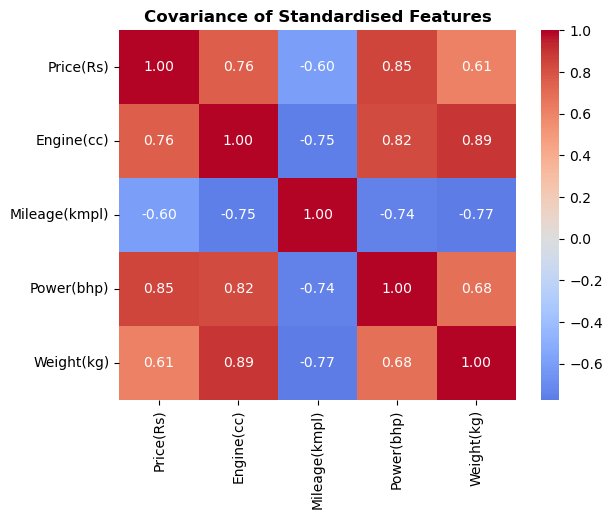

In [75]:
z = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()
print(z.cov().round(2))   


sns.heatmap(z.cov(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Covariance of Standardised Features', fontweight='bold'); plt.show()